In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
from plotly.subplots import make_subplots
import plotly.graph_objects as go
import plotly.express as px

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression,Ridge
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [3]:
df =  pd.read_csv('Hos_data.csv')

In [4]:
df.head()

,Name,District,ABDM Enables,Ownership,Facility Type,No of beds,Landline/mobile phone,No. of Ventilators,System of Medicine,Address,Open 24 hrs,Pincode
0,32 INTACT Multispeciality Dental clinic,Bhilaspur,No,Private,Dental Clinic,NaN,mobile,NaN,Dentistry,"H2 44 Narmada Nagar , Bilaspur, Chhattisgarh -...",No,495001.0
1,27 Kholi,Bhilaspur,No,Government,Sub Centre,1,NaN,0,Modern Medicine(Allopathy),"27 kholi vikash nagar bilaspur, Bilaspur, Chha...",No,495001.0
2,Agrawal Children Hoospital,Bhilaspur,No,Private,Hospital,15,mobile,1,Modern Medicine(Allopathy),Agrawal Children Hospital 11/363/1 Magarpara R...,Yes,495001.0
3,Aakash Patholab collection center,Bhilaspur,No,Private,Diagnostic Laboratory,0,mobile,0,Modern Medicine(Allopathy),"near Jain temple Main road sarkanda bilaspur ,...",No,495001.0
4,Aaradhya Hospital,Bhilaspur,No,Private,Hospital,100,2,5,Modern Medicine(Allopathy),MAHAMAYA CHOWK RATANPUR ROAD SARKANDA BILASPUR...,Yes,495001.0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99 entries, 0 to 98
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Name                   98 non-null     object 
 1   District               99 non-null     object 
 2   ABDM Enables           98 non-null     object 
 3   Ownership              97 non-null     object 
 4   Facility Type          98 non-null     object 
 5   No of beds             88 non-null     object 
 6   Landline/mobile phone  77 non-null     object 
 7   No. of Ventilators     86 non-null     object 
 8   System of Medicine     98 non-null     object 
 9   Address                97 non-null     object 
 10  Open 24 hrs            98 non-null     object 
 11  Pincode                97 non-null     float64
dtypes: float64(1), object(11)
memory usage: 9.4+ KB


### Data Cleaning & Preparation

Adjusting Metric names

In [6]:
df.columns = df.columns.str.strip().str.replace(" ", "_").str.replace(".", "", regex=False)

print(df.columns)

Index(['Name', 'District', 'ABDM_Enables', 'Ownership', 'Facility_Type',
       'No_of_beds', 'Landline/mobile_phone', 'No_of_Ventilators',
       'System_of_Medicine', 'Address', 'Open_24_hrs', 'Pincode'],
      dtype='object')


Removing duplicates and handling missing values

In [7]:
df.drop_duplicates(inplace=True)

In [8]:
df.isna().sum()

Name                      1
District                  0
ABDM_Enables              1
Ownership                 2
Facility_Type             1
No_of_beds               11
Landline/mobile_phone    22
No_of_Ventilators        13
System_of_Medicine        1
Address                   2
Open_24_hrs               1
Pincode                   2
dtype: int64

In [9]:
df.replace(["NA", "N/A", "--", "Not Available", ""], pd.NA, inplace=True)

handling Column

In [10]:
df['Landline/mobile_phone'] = df['Landline/mobile_phone'].replace({'2':'Landline/Mobile Phone','mobile':'Mobile Phone'})

Adjusting data types

In [11]:
cat_cols = ["District", "Ownership", "Facility_Type", "System_of_Medicine","Landline/mobile_phone"]
for col in cat_cols:
    df[col] = df[col].astype("category")

In [12]:
df["ABDM_Enables"] = df["ABDM_Enables"].str.strip().str.lower().map({
    "yes": True, "no": False
})

df["Open_24_hrs"] = df["Open_24_hrs"].str.strip().str.lower().map({
    "yes": True, "no": False
})

In [13]:
df["No_of_beds"] = pd.to_numeric(df["No_of_beds"], errors="coerce")
df["No_of_Ventilators"] = pd.to_numeric(df["No_of_Ventilators"], errors="coerce")

In [14]:
df['Pincode'] = df['Pincode'].dropna().astype(int)

In [15]:
df["Name"] = df["Name"].astype(str).str.strip()
df["Address"] = df["Address"].astype(str).str.strip()

In [16]:
df["No_of_Ventilators"].fillna(0, inplace=True)

In [17]:
df.head()

,Name,District,ABDM_Enables,Ownership,Facility_Type,No_of_beds,Landline/mobile_phone,No_of_Ventilators,System_of_Medicine,Address,Open_24_hrs,Pincode
0,32 INTACT Multispeciality Dental clinic,Bhilaspur,False,Private,Dental Clinic,NaN,Mobile Phone,0.0,Dentistry,"H2 44 Narmada Nagar , Bilaspur, Chhattisgarh -...",False,495001.0
1,27 Kholi,Bhilaspur,False,Government,Sub Centre,1.0,NaN,0.0,Modern Medicine(Allopathy),"27 kholi vikash nagar bilaspur, Bilaspur, Chha...",False,495001.0
2,Agrawal Children Hoospital,Bhilaspur,False,Private,Hospital,15.0,Mobile Phone,1.0,Modern Medicine(Allopathy),Agrawal Children Hospital 11/363/1 Magarpara R...,True,495001.0
3,Aakash Patholab collection center,Bhilaspur,False,Private,Diagnostic Laboratory,0.0,Mobile Phone,0.0,Modern Medicine(Allopathy),"near Jain temple Main road sarkanda bilaspur ,...",False,495001.0
4,Aaradhya Hospital,Bhilaspur,False,Private,Hospital,100.0,Landline/Mobile Phone,5.0,Modern Medicine(Allopathy),MAHAMAYA CHOWK RATANPUR ROAD SARKANDA BILASPUR...,True,495001.0


In [18]:
df.dtypes

Name                       object
District                 category
ABDM_Enables               object
Ownership                category
Facility_Type            category
No_of_beds                float64
Landline/mobile_phone    category
No_of_Ventilators         float64
System_of_Medicine       category
Address                    object
Open_24_hrs                object
Pincode                   float64
dtype: object

#### Exploratory Data Analysis

In [19]:
beds_counts = df['No_of_beds'].value_counts()

second_mode_beds = beds_counts.index[1]

vent_counts = df['No_of_Ventilators'].value_counts()

second_mode_vent = vent_counts.index[1]
second_mode_vent,second_mode_beds

(np.float64(1.0), np.float64(10.0))

In [20]:
df['ABDM_Enables'].mean()

np.float64(0.41237113402061853)

In [21]:
print(df['Facility_Type'].value_counts())
print('-'*60)
print(df['Ownership'].value_counts())
print('-'*60)
print(df['District'].value_counts())

Facility_Type
Hospital                                                46
Dental Clinic                                           11
Ayurveda Dispensary/ Clinic/ Polyclinic (OPD only)       8
Primary Health Centre                                    7
Clinic/ Dispensary                                       6
Sub Centre                                               6
Health and Wellness Centre                               4
 \r\n\r\nPharmacy                                        3
Diagnostic Laboratory                                    2
Ayurveda                                                 1
\r\nPhysiotherapy Clinic                                 1
Homeopathy Dispensary/ Clinic/ Polyclinic (OPD only)     1
Medical College                                          1
Name: count, dtype: int64
------------------------------------------------------------
Ownership
Private       69
Government    27
Name: count, dtype: int64
------------------------------------------------------------
D

In [22]:
df.nunique()

Name                     97
District                  3
ABDM_Enables              2
Ownership                 2
Facility_Type            13
No_of_beds               23
Landline/mobile_phone     4
No_of_Ventilators        11
System_of_Medicine       12
Address                  97
Open_24_hrs               2
Pincode                  28
dtype: int64

In [23]:
fig = px.pie(df, names="Facility_Type",
             title="Distribution of Facility Types",color_discrete_sequence=px.colors.qualitative.Set3
)
fig.show()

#### Insights
- The dataset includes a diverse set of healthcare facilities such as clinics, pharmacies, diagnostic labs, and wellness centers, reflecting the variety in the healthcare ecosystem.
- Hospitals constitute the largest share (~46%) of the dataset, indicating that the data is heavily skewed towards hospital-based facilities.

In [24]:
fig = px.pie(df, names='System_of_Medicine',
             title="Distribution of System of Medicine",color_discrete_sequence=px.colors.qualitative.Set3)
fig.show()

#### Insights
- The distribution indicates that Allopathy is the dominant system of medicine, highlighting a strong reliance on modern healthcare infrastructure for treatment and emergency services.
- The chart shows that while Modern Medicine dominates, there are multiple smaller segments representing combinations like Modern Medicine with Dentistry, Physiotherapy, and Homeopathy, indicating that some hospitals provide multiple systems of medicine within the same facility.
- Traditional systems such as Ayurveda and Homeopathy contribute a smaller but significant portion, indicating continued public trust and cultural importance of alternative medicine.
- The presence of multiple systems of medicine reflects a diverse healthcare ecosystem, offering patients a variety of treatment choices.

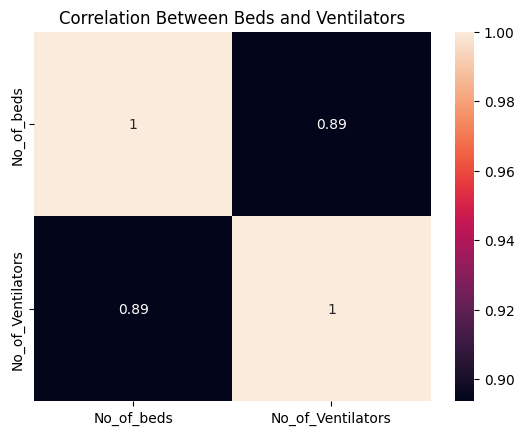

In [25]:
num_df = df[['No_of_beds', 'No_of_Ventilators']]

sns.heatmap(num_df.corr(), annot=True)

plt.title("Correlation Between Beds and Ventilators")
plt.show()

The correlation value very high, meaning:

- Hospitals with more beds usually have more ventilators.This shows positive correlation between them
- As bed capacity increases, ventilator count also tends to increase.

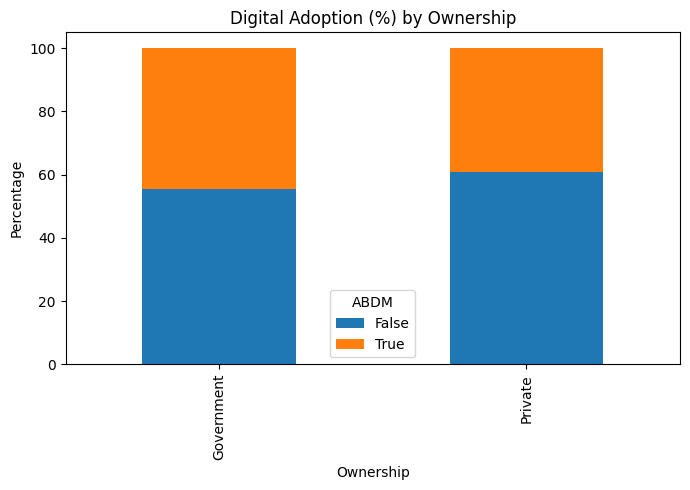

In [26]:
ct = pd.crosstab(df['Ownership'], df['ABDM_Enables'], normalize='index') * 100
ct.plot(kind='bar', stacked=True, figsize=(7,5))

plt.title("Digital Adoption (%) by Ownership")
plt.ylabel("Percentage")
plt.legend(title="ABDM")
plt.tight_layout()
plt.show()

#### Insights
The chart shows that digital adoption (ABDM enabled facilities) is relatively similar across both ownership categories. Private hospitals have a slightly higher percentage of non-adopted facilities compared to government hospitals. Government hospitals demonstrate marginally better ABDM implementation rates. Overall, the results suggest that digital adoption is progressing in both sectors, but further expansion is still needed.

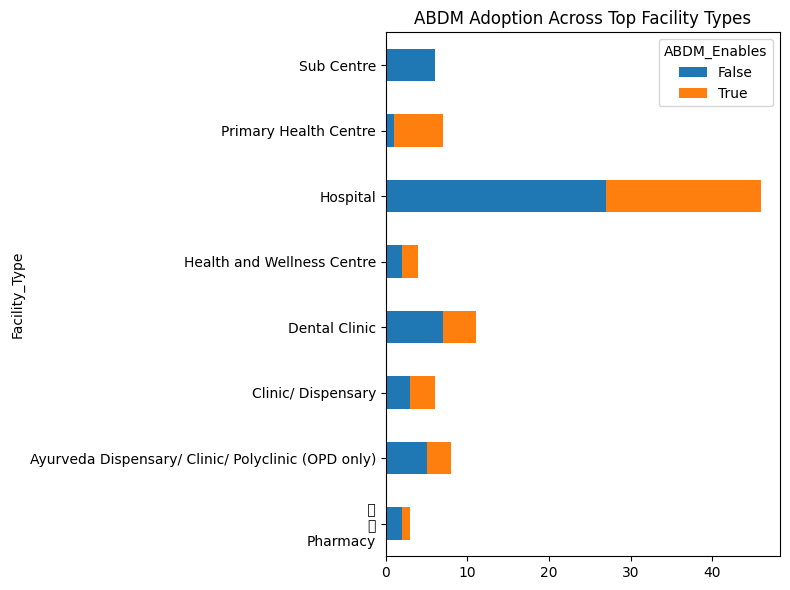

In [27]:
top_types = df['Facility_Type'].value_counts().head(8).index
filtered = df[df['Facility_Type'].isin(top_types)]

ct = pd.crosstab(filtered['Facility_Type'], filtered['ABDM_Enables'])
ct.plot(kind='barh', stacked=True, figsize=(8,6))

plt.title("ABDM Adoption Across Top Facility Types")
plt.tight_layout()
plt.show()

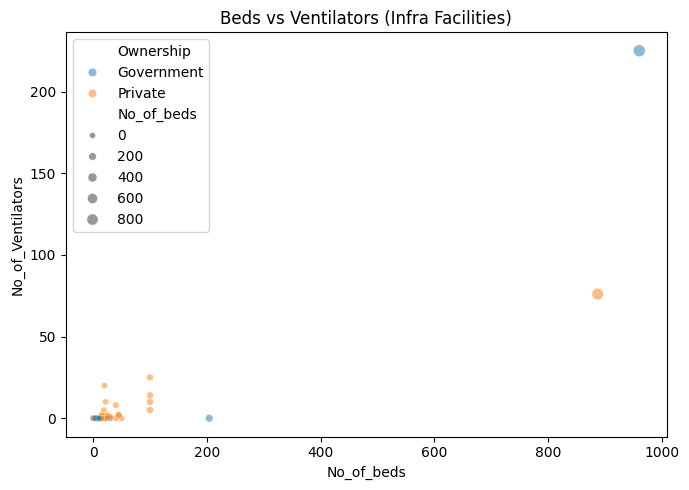

In [28]:
plt.figure(figsize=(7,5))
sns.scatterplot(
    data=df,
    x='No_of_beds',
    y='No_of_Ventilators',
    hue='Ownership',
    size='No_of_beds',
alpha=0.5)

plt.title("Beds vs Ventilators (Infra Facilities)")
plt.tight_layout()
plt.show()

#### Insights
- Beds and ventilators show a positive relationship.
- Most hospitals have low beds and low ventilators.
- Few high-capacity hospitals act as outliers.
- Ventilator distribution is uneven across hospitals.
- Private hospitals show more variation, while government includes some large facilities.

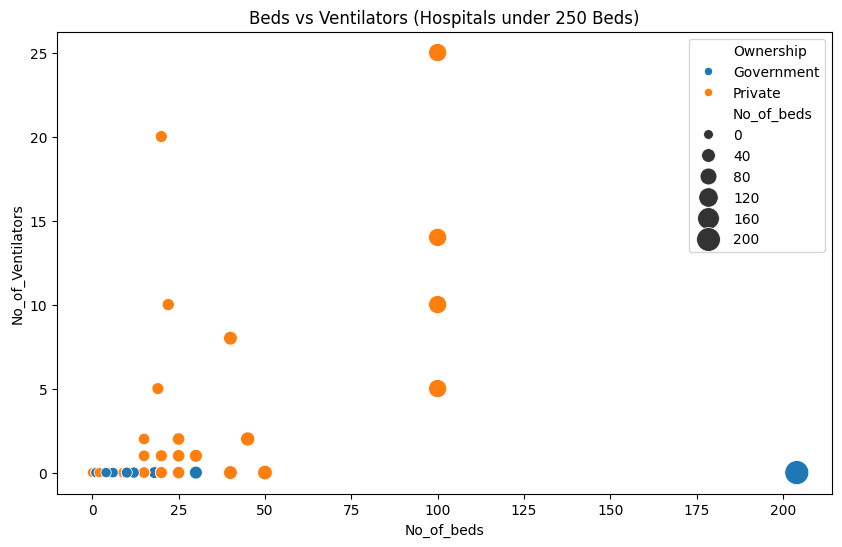

In [29]:
small_df = df[df['No_of_beds'] < 250]

plt.figure(figsize=(10,6))

sns.scatterplot(
    data=small_df,
    x='No_of_beds',
    y='No_of_Ventilators',
    hue='Ownership',
    size='No_of_beds',
    sizes=(50,300)
)

plt.title("Beds vs Ventilators (Hospitals under 250 Beds)")
plt.show()

#### Insights
- Several hospitals with 20–50 beds still have zero ventilators, indicating that bed capacity alone does not ensure critical-care preparedness.
- Hospitals with similar bed counts show very different ventilator availability, suggesting uneven resource allocation, differences in funding, ownership, or specialization.
- Many hospitals operate with minimal ventilator support (0–2 units), which could increase pressure on larger hospitals during emergencies or sudden patient surges.
- Some mid-sized hospitals around 100 beds have relatively high ventilator counts, indicating that certain facilities may serve as emergency or specialty care centers.

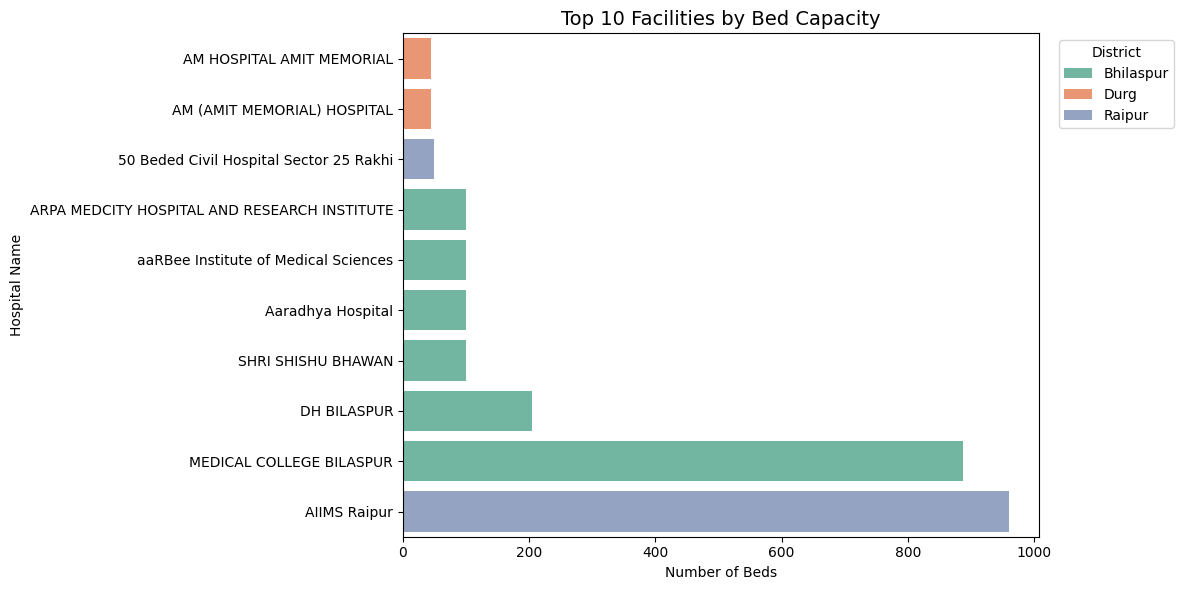

In [30]:
top10 = df.sort_values(by='No_of_beds', ascending=False).head(10)

plt.figure(figsize=(12,6))

sns.barplot(
    data=top10,
    x='No_of_beds',
    y='Name',
    hue='District',
    dodge=False,
    palette='Set2'
)

plt.title("Top 10 Facilities by Bed Capacity", fontsize=14)
plt.xlabel("Number of Beds")
plt.ylabel("Hospital Name")
plt.gca().invert_yaxis()   # highest on top
plt.legend(title="District", bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

#### Insights  should change if needed 
- The hospital bed distribution is highly uneven. AIIMS Raipur and Medical College Bilaspur account for the majority of available beds, while most other facilities have significantly lower capacity.And both of them are Medical Colleges.
- After the top two hospitals, bed capacity declines sharply, with DH Bilaspur having only around 200 beds, which indicates that healthcare infrastructure is heavily concentrated in a few major institutions.
- The mid-ranked hospitals, particularly those placed from 4th to 7th, have capacities ranging between 90 and 110 beds, suggesting moderate service capability but still significantly smaller than the leading hospitals. Meanwhile, the lower-ranked facilities have only 30 to 50 beds, reflecting limited capacity and indicating that these are likely smaller community hospitals or local healthcare centers serving basic medical needs.

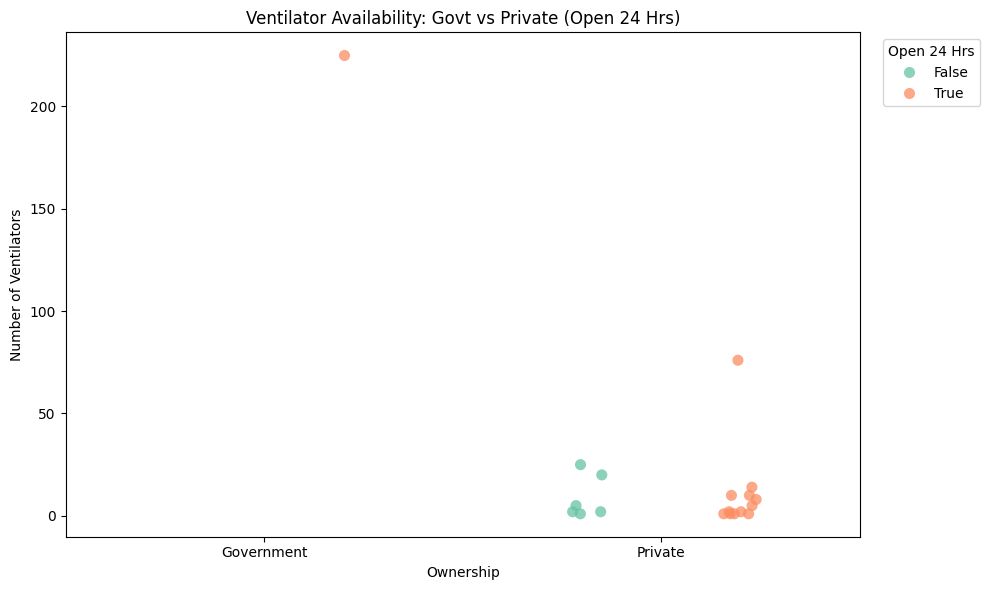

In [31]:
filtered_df = df[df['No_of_Ventilators'] > 0].copy()
plt.figure(figsize=(10,6))

sns.stripplot(
    data=filtered_df,
    x='Ownership',
    y='No_of_Ventilators',
    hue='Open_24_hrs',
    dodge=True,
    jitter=True,
    size=8,
    alpha=0.75,
    palette='Set2'
)

plt.title("Ventilator Availability: Govt vs Private (Open 24 Hrs)")
plt.xlabel("Ownership")
plt.ylabel("Number of Ventilators")
plt.legend(title="Open 24 Hrs", bbox_to_anchor=(1.02,1), loc='upper left')
plt.tight_layout()
plt.show()

#### Insights
- Government hospitals are few in this filtered dataset but include the highest-capacity facility, with one 24-hour government hospital having exceptionally high ventilator availability (around 225), indicating concentration of advanced critical-care resources in select public institutions.
- Private hospitals are more numerous and spread across low to moderate ventilator counts, suggesting they play a broader role in routine healthcare delivery rather than concentrating very large critical-care capacity.
- Among private hospitals, 24-hour facilities generally appear to have higher ventilator counts than non-24-hour facilities, implying that round-the-clock operations are associated with better emergency readiness.

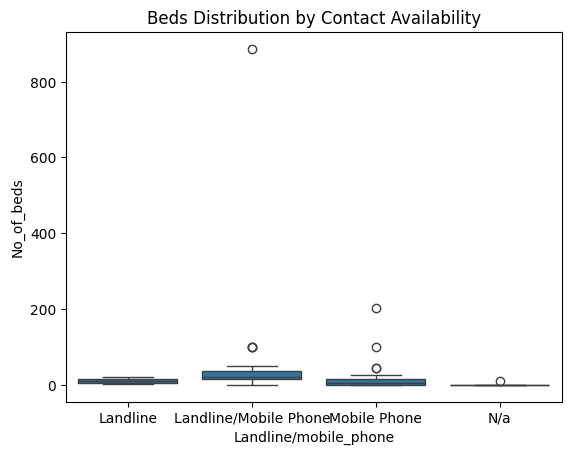

In [32]:
plot_df = df.dropna(subset=['No_of_beds', 'No_of_Ventilators'])
sns.boxplot(
    data=plot_df,
    x='Landline/mobile_phone',
    y='No_of_beds'
)
plt.title("Beds Distribution by Contact Availability")
plt.show()

#### Insights
- Facilities with Landline/Mobile Phone availability show the widest spread and the highest median bed capacity, indicating that hospitals with multiple communication channels tend to be larger and better equipped. This category also contains an extreme outlier near 900 beds, likely representing a major tertiary hospital or medical college.

- Facilities with only Mobile Phone availability have mostly low-to-moderate bed counts, though a few outliers around 100–200 beds suggest some medium-sized hospitals operate primarily through mobile contact.

- Hospitals with only Landline access generally have lower and more compact bed distributions, indicating smaller or more traditional facilities with limited scale.

- The N/A category shows almost zero bed capacity in most cases, suggesting missing contact information is common among very small centers, inactive units, or incomplete records.

#### Model Building

In [33]:
filtered_df = df[df['No_of_Ventilators'] > 0].copy()

print("Rows after ventilator filter:", len(filtered_df))

Rows after ventilator filter: 19


In [34]:
filtered_df['Ownership'] = filtered_df['Ownership'].replace({
    'Government':1,
    'Private':0,
})

filtered_df['Open_24_hrs'] = filtered_df['Open_24_hrs'].replace({
'True':1,
'False':0
})

filtered_df = filtered_df.dropna(subset=[
    'No_of_beds','No_of_Ventilators','Ownership','Open_24_hrs'
])

In [35]:
X = filtered_df[['No_of_beds', 'Ownership', 'Open_24_hrs']]
y = filtered_df['No_of_Ventilators']
test_size = 0.2 if len(filtered_df) >= 10 else 0.33

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=test_size,
    random_state=42
)

print("Train rows:", len(X_train))
print("Test rows:", len(X_test))

Train rows: 15
Test rows: 4


In [36]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0)
}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    print(name)
    print("R2   :", round(r2_score(y_test, pred),3))
    print("MAE  :", round(mean_absolute_error(y_test, pred),3))
    print("RMSE :", round(np.sqrt(mean_squared_error(y_test, pred)),3))
    print("-"*30)

Linear Regression
R2   : -2.044
MAE  : 3.235
RMSE : 3.489
------------------------------
Ridge Regression
R2   : -3.717
MAE  : 2.643
RMSE : 4.344
------------------------------


#### Data Visualization/Dash boarding

In [40]:

districts_covered = df["District"].nunique()

digitalization = round(
    df["ABDM_Enables"].astype(str).str.lower().isin(
        ["yes","true","1","enabled"]
    ).mean()*100,1
)

open_24hrs = round(
    df["Open_24_hrs"].astype(str).str.lower().isin(
        ["yes","true","1","open"]
    ).mean()*100,1
)

top_beds = int(df["No_of_beds"].max())

fig = make_subplots(
    rows=3,
    cols=4,
    row_heights=[0.18,0.41,0.41],
    vertical_spacing=0.08,
    horizontal_spacing=0.08,
    specs=[
        [{"type":"indicator"},{"type":"indicator"},{"type":"indicator"},{"type":"indicator"}],
        [{"type":"bar","colspan":2},None,{"type":"scatter","colspan":2},None],
        [{"type":"domain","colspan":2},None,{"type":"box","colspan":2},None]
    ],
    subplot_titles=(
        "Districts Covered",
        "Digitalization",
        "Open 24 Hrs",
        "Highest Bed Capacity",
        "Top 10 Facilities by Bed Capacity",
        "Beds vs Ventilators",
        "Distribution of Facility Types",
        "Beds Distribution by Contact Availability"
    )
)

fig.add_trace(
    go.Indicator(
        mode="number",
        value=districts_covered,
        number={"font":{"size":28,"color":"#16a34a"}}
    ),
    row=1,col=1
)

fig.add_trace(
    go.Indicator(
        mode="number",
        value=digitalization,
        number={"suffix":"%","font":{"size":28,"color":"#7c3aed"}}
    ),
    row=1,col=2
)

fig.add_trace(
    go.Indicator(
        mode="number",
        value=open_24hrs,
        number={"suffix":"%","font":{"size":28,"color":"#dc2626"}}
    ),
    row=1,col=3
)

fig.add_trace(
    go.Indicator(
        mode="number",
        value=top_beds,
        number={"font":{"size":28,"color":"#2563eb"}}
    ),
    row=1,col=4
)

top10 = df.sort_values(by="No_of_beds", ascending=False).head(10)

bar = px.bar(
    top10,
    x="No_of_beds",
    y="Name",
    orientation="h",
    color="No_of_beds",
    color_continuous_scale="Blues"
)

for tr in bar.data:
    fig.add_trace(tr,row=2,col=1)

small_df = df[df["No_of_beds"] < 250]

sc = px.scatter(
    small_df,
    x="No_of_beds",
    y="No_of_Ventilators",
    size="No_of_beds",
    color="No_of_Ventilators",
    hover_name="Name",
    color_continuous_scale="Viridis"
)

for tr in sc.data:
    fig.add_trace(tr,row=2,col=3)

pie = px.pie(
    df,
    names="Facility_Type",
    hole=0.45,
    color_discrete_sequence=px.colors.qualitative.Set3
)

for tr in pie.data:
    fig.add_trace(tr,row=3,col=1)

bx = px.box(
    df,
    x="Landline/mobile_phone",
    y="No_of_beds",
    color="Landline/mobile_phone"
)

for tr in bx.data:
    fig.add_trace(tr,row=3,col=3)

fig.update_yaxes(autorange="reversed", row=2, col=1)

fig.update_layout(
    title={
        "text":"🏥 Health Care Analysis",
        "x":0.5,
        "font":{"size":30}
    },
    template="plotly_white",
    height=1200,
    width=1500,
    showlegend=False,
    font=dict(size=11),
    margin=dict(l=30,r=30,t=80,b=30)
)

fig.show()

In [41]:
fig.write_image("healthcare_dashboard_hd.png", scale=5, width=1800, height=1400)